Autor: Jonathan Higueros Garrido  
País: Guatemala  
Fecha: 06/10/2026  
e-mail: jonathanhigueros@yahoo.com  

## Fuente:
[All Nobel Prizes in Literature](https://www.nobelprize.org/prizes/lists/all-nobel-prizes-in-literature/)

# Premio Nobel de Literatura (1901–2025)
## Análisis exploratorio de datos, calidad de registros y evaluación de escenarios

### Objetivo
Este estudio analiza los registros del Premio Nobel de Literatura entre 1901 y 2025 para caracterizar:
* La distribución geográfica y lingüística de los galardonados.
* La representación por género a lo largo de la historia.
* La edad al momento de recibir la distinción.
* La evolución de estas variables en las últimas dos décadas (2006–2025).
* Las relaciones bivariadas entre género, continente e idioma de la obra.
* La viabilidad y fundamento de los escenarios planteados para el perfil de la edición 2026.

> **Nota metodológica:** El análisis es de naturaleza **descriptiva y exploratoria**. Los patrones observados en la serie histórica describen comportamientos pasados de la Academia Sueca, pero no constituyen una norma matemática fija ni permiten calcular una probabilidad predictiva exacta sin asumir supuestos explícitos.

## 1. Introducción y contexto

El Premio Nobel de Literatura constituye una serie histórica de gran valor para el análisis de datos, ya que condensa variables demográficas, temporales, geográficas y culturales a lo largo de más de un siglo.

La pregunta central que guía este proyecto se formula de la siguiente manera:

> **¿Qué patrones descriptivos caracterizan históricamente a los ganadores del Premio Nobel de Literatura y qué tan estables son esos patrones en el período reciente?**

De manera complementaria, nos planteamos:

> **¿Qué características se presentan con mayor frecuencia entre los ganadores recientes y qué escenario histórico resultaría compatible con ellas para la edición de 2026?**

Esta segunda interrogante debe entenderse estrictamente como una **evaluación de escenarios prospectivos**, no como un pronóstico determinista.

## 2. Alcance y unidad de análisis

El conjunto de datos comprende **122 personas galardonadas**, correspondientes a **118 años de concesión** del premio entre 1901 y 2025.

La diferencia entre ambas cifras se explica porque en cuatro ocasiones (1904, 1917, 1966 y 1974) el premio fue compartido por dos personas.

Por lo tanto, la estructura del estudio se define así:
* **Unidad de observación principal:** Persona galardonada.
* **Unidad temporal:** Año de concesión.
* **Período histórico global:** 1901–2025 (122 registros).
* **Período reciente de comparación:** 2006–2025 (20 años de concesión, 20 personas).

Conservar los cuatro premios compartidos es fundamental para no distorsionar las proporciones demográficas y geográficas reales de la historia del galardón.

## 3. Metodología

El desarrollo del trabajo se organiza en seis fases secuenciales:
1. **Carga y auditoría de calidad de datos.**
2. **Construcción y validación de variables derivadas.**
3. **Análisis univariado:** género, continente, nacionalidad, idioma y edad.
4. **Comparación entre el acumulado histórico y el período reciente.**
5. **Análisis bivariado:** interacción entre género frente a continente e idioma.
6. **Evaluación de patrones de alternancia y construcción de escenarios para 2026.**

### Variable derivada
La edad al recibir el galardón se calcula formalmente como:

$$\text{Edad al ganar} = \text{Año de concesión} - \text{Año de nacimiento}$$

Esta variable nos permite medir cuantitativamente la madurez artística y la trayectoria acumulada de los premiados.

In [9]:
# ============================================================
# 4. Librerías y carga de datos
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive

# 1. Montar Google Drive
drive.mount('/content/drive')

# 2. Ruta al archivo dentro de tu Drive
ruta = "/content/drive/My Drive/Colab Notebooks/Nobel/nobel_literatura.csv"

# 3. Leer el archivo CSV
df = pd.read_csv(ruta)

# 4. Ver las primeras filas
# print(df.head())

nobel = df.copy()
nobel.head()

Mounted at /content/drive


,Año,Nombre,Nacionalidad,Continente,Género,Nacimiento,Edad_al_ganar,Idioma
0,2025,László Krasznahorkai,Hungría,Europa,Masculino,1954,71,Húngaro
1,2024,Han Kang,Corea del Sur,Asia,Femenino,1970,54,Coreano
2,2023,Jon Fosse,Noruega,Europa,Masculino,1959,64,Noruego (nynorsk)
3,2022,Annie Ernaux,Francia,Europa,Femenino,1940,82,Francés
4,2021,Abdulrazak Gurnah,Tanzania,África,Masculino,1948,73,Inglés


## 5. Auditoría inicial de calidad de datos

Antes de interpretar los resultados, se realiza una verificación exhaustiva del conjunto de datos:
* Cantidad de filas y columnas.
* Confirmación de tipos de datos por columna.
* Ausencia de valores nulos o faltantes.
* Identificación de registros duplicados o premios compartidos.
* Verificación del rango temporal (1901–2025).
* Consistencia en la clasificación de género, continente e idioma.

Esta fase de auditoría garantiza que las agrupaciones geográficas y lingüísticas no contengan sesgos derivados de errores de digitalización o codificación.

In [4]:
print(f"El dataset tiene {nobel.shape[0]} filas y {nobel.shape[1]} columnas")

El dataset tiene 122 filas y 8 columnas


In [5]:
# Tipos de datos
nobel.dtypes

,0
Año,int64
Nombre,object
Nacionalidad,object
Continente,object
Género,object
Nacimiento,int64
Edad_al_ganar,int64
Idioma,object


In [6]:
# Valores nulos
print(nobel.isna().sum())  # Cuenta los faltantes por columna
print(nobel.info())        # Resumen con valores no nulos

Año              0
Nombre           0
Nacionalidad     0
Continente       0
Género           0
Nacimiento       0
Edad_al_ganar    0
Idioma           0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Año            122 non-null    int64 
 1   Nombre         122 non-null    object
 2   Nacionalidad   122 non-null    object
 3   Continente     122 non-null    object
 4   Género         122 non-null    object
 5   Nacimiento     122 non-null    int64 
 6   Edad_al_ganar  122 non-null    int64 
 7   Idioma         122 non-null    object
dtypes: int64(3), object(5)
memory usage: 7.8+ KB
None


In [7]:
# Duplicados
nobel["Año"].value_counts()[nobel["Año"].value_counts() > 1]
# Los años duplicados corresponden a los años en los que el
# Premio Nobel de Literatura fue compartido.

,count
Año,
1974,2
1966,2
1904,2
1917,2


In [8]:
print("\nRango de años:", nobel["Año"].min(), "–", nobel["Año"].max())


Rango de años: 1901 – 2025


In [9]:
# Años de concesión
nobel["Año"].nunique()

118

In [10]:
# Personas premiadas
nobel["Nombre"].nunique()

122

In [11]:
print("\nGéneros registrados:")
display(nobel["Género"].value_counts(dropna=False))


Géneros registrados:


,count
Género,
Masculino,104
Femenino,18


In [12]:
# Nacionalidades distintas
nobel['Nacionalidad'].nunique()

44

## 6. Análisis descriptivo global

### 6.1 Distribución continental y por país

El análisis geográfico evidencia una notable concentración histórica en el continente europeo. Esta característica describe la trayectoria del galardón a lo largo del siglo XX, fruto del origen de la institución y de sus redes de nominación, aunque no debe interpretarse como una norma fija de la Academia.

En cuanto a los países más representados en la base, Francia lidera la distribución con 15 galardonados ($12.3\%$), seguida de Estados Unidos y el Reino Unido (10 cada uno, $8.2\%$), Alemania (9, $7.4\%$) y Suecia (7, $5.7\%$).

In [13]:
continentes = nobel.groupby("Continente")["Nombre"].count().reset_index()

# Renombrar las columnas
continentes = continentes.rename(columns={
    "Continente": "Continentes",
    "Nombre": "Conteo"})

# Porcentaje
continentes["%"] = round(continentes["Conteo"] / continentes["Conteo"].sum() * 100, 2)

# Ordenar de mayor a menor
continentes = continentes.sort_values(by="Conteo", ascending=False)

print(continentes)

  Continentes  Conteo      %
2      Europa      89  72.95
0     América      19  15.57
1        Asia       8   6.56
4      África       5   4.10
3     Oceanía       1   0.82


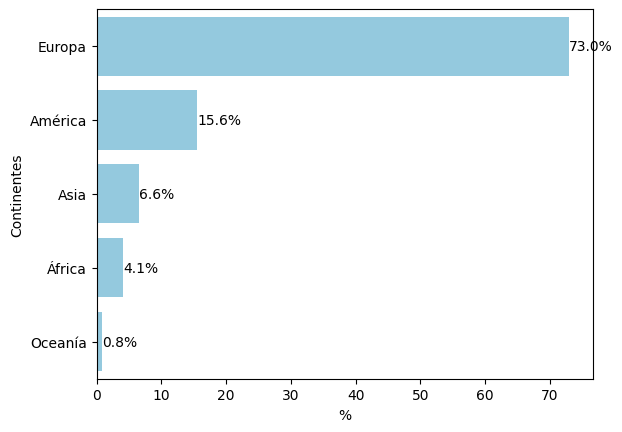

In [14]:
ax = sns.barplot(x=continentes["%"], y=continentes["Continentes"], color="skyblue")

# Agregar etiquetas con el porcentaje
ax.bar_label(ax.containers[0],
             labels=continentes["%"].round(1).astype(str) + "%",
             label_type="edge")
plt.show()

In [15]:
paises = nobel.groupby("Nacionalidad")["Nombre"].count().reset_index()

# Renombrar las columnas
paises = paises.rename(columns={
    "Nacionalidad": "País",
    "Nombre": "Conteo"})

# Porcentaje
paises["%"] = round(paises["Conteo"] / paises["Conteo"].sum() * 100, 2)

# Ordenar de mayor a menor
paises = paises.sort_values(by="Conteo", ascending=False)

print(paises.head(10))

              País  Conteo      %
17         Francia      15  12.30
15  Estados Unidos      10   8.20
33     Reino Unido      10   8.20
0         Alemania       9   7.38
39          Suecia       7   5.74
25          Italia       6   4.92
31         Polonia       6   4.92
36           Rusia       5   4.10
14          España       5   4.10
29         Noruega       4   3.28


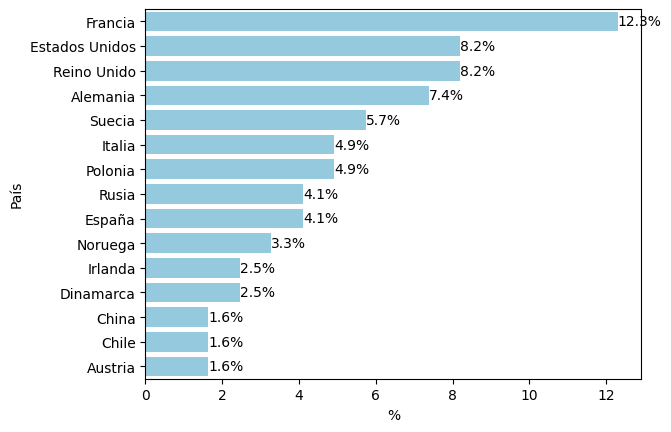

In [16]:
ax = sns.barplot(x=paises["%"].head(15), y=paises["País"].head(15), color="skyblue")

# Agregar etiquetas con el porcentaje
ax.bar_label(ax.containers[0],
             labels=paises["%"].head(15).round(1).astype(str) + "%",
             label_type="edge")
plt.show()

### 6.2 Distribución por género

En el acumulado histórico de 122 premiados, la base registra **18 mujeres** y **104 hombres**.

Esto se traduce en las siguientes proporciones globales:
* **Hombres:** $85.25\%$ (104 galardonados)
* **Mujeres:** $14.75\%$ (18 galardonadas)

Si bien los datos globales muestran una asimetría histórica pronunciada, el análisis por periodos temporales revela que esta distribución ha cambiado de manera considerable en las décadas más recientes.

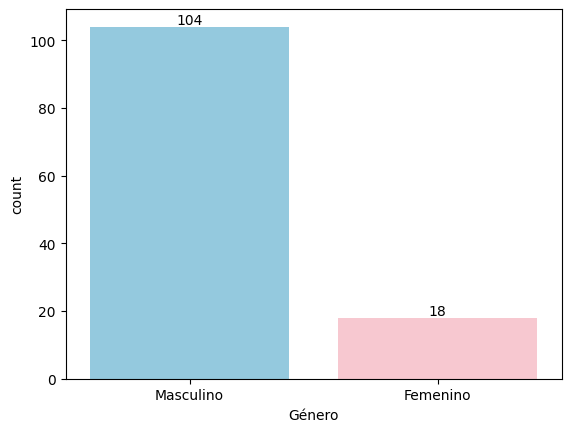

In [17]:
paleta_colores = {"Masculino": "skyblue", "Femenino": "pink"}
ax = sns.countplot(data=nobel, x="Género", hue="Género", palette=paleta_colores)
# Agregar las etiquetas con los totales sobre cada barra
for p in ax.containers:
    ax.bar_label(p)
plt.show()

## 7. Evolución de la representación por género por década

Examinar las proporciones de género desglosadas por década resulta mucho más revelador que observar únicamente el total consolidado.

Durante la mayor parte del siglo XX, la presencia femenina fue mínima o inexistente en varios decenios (por ejemplo, $0\%$ en las décadas de 1910, 1950, 1970 y 1980). No obstante, a partir de la década de 1990 la proporción de mujeres galardonadas comenzó a incrementarse de forma sostenida, alcanzando un $30\%$ en los decenios de 1990, 2000 y 2010, y llegando a un **$50\%$ en lo que va de la década de 2020**.

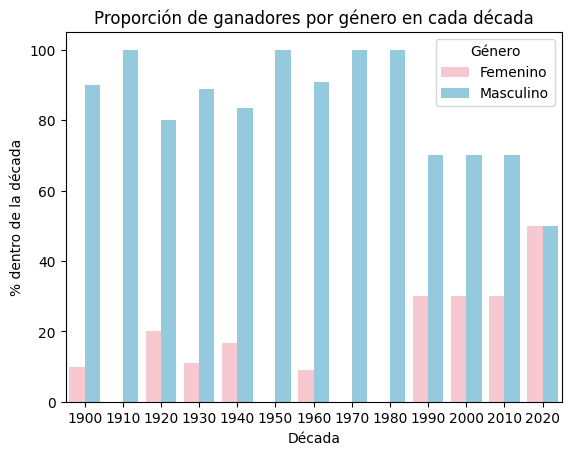

In [18]:
# Agrupar por década y género
nobel["Década"] = (nobel["Año"] // 10) * 10
decadas = nobel.groupby(["Década", "Género"]).size().reset_index(name="Conteo")

# Calcular proporción dentro de cada década
decadas["Proporción"] = decadas.groupby("Década")["Conteo"].transform(lambda x: x / x.sum() * 100)

paleta_colores = {"Masculino": "skyblue", "Femenino": "pink"}
ax = sns.barplot(data=decadas, x="Década", y="Proporción", hue="Género", palette=paleta_colores)
plt.title("Proporción de ganadores por género en cada década")
plt.ylabel("% dentro de la década")
plt.show()


In [19]:
# Parece que a partir de 2010 se empieza a premiar con cierta altenancia de género
alternancia = nobel[nobel["Año"] >= 2010]
alternancia.head(10)
# Se puede apreciar que a partir de 2018 hay una alternancia perfecta

,Año,Nombre,Nacionalidad,Continente,Género,Nacimiento,Edad_al_ganar,Idioma,Década
0,2025,László Krasznahorkai,Hungría,Europa,Masculino,1954,71,Húngaro,2020
1,2024,Han Kang,Corea del Sur,Asia,Femenino,1970,54,Coreano,2020
2,2023,Jon Fosse,Noruega,Europa,Masculino,1959,64,Noruego (nynorsk),2020
3,2022,Annie Ernaux,Francia,Europa,Femenino,1940,82,Francés,2020
4,2021,Abdulrazak Gurnah,Tanzania,África,Masculino,1948,73,Inglés,2020
5,2020,Louise Glück,Estados Unidos,América,Femenino,1943,77,Inglés,2020
6,2019,Peter Handke,Austria,Europa,Masculino,1942,77,Alemán,2010
7,2018,Olga Tokarczuk,Polonia,Europa,Femenino,1962,56,Polaco,2010
8,2017,Kazuo Ishiguro,Reino Unido,Europa,Masculino,1954,63,Inglés,2010
9,2016,Bob Dylan,Estados Unidos,América,Masculino,1941,75,Inglés,2010


## 8. Distribución por idioma de la obra

El idioma de las obras galardonadas muestra una representación destacada del **inglés** ($24.6\%$, 30 galardonados), seguido por el **francés** ($12.3\%$, 15), el **alemán** ($11.5\%$, 14) y el **español** ($9.0\%$, 11).

Es fundamental mantener las categorías de idiomas exactamente como están codificadas en el registro (por ejemplo, preservando distinciones como `Noruego` frente a `Noruego (nynorsk)`), para evitar alterar los datos originales con criterios arbitrarios de unificación.


In [20]:
idiomas = nobel.groupby("Idioma")["Nombre"].count().reset_index()

# Renombrar las columnas
idiomas = idiomas.rename(columns={
    "Idioma": "Idioma",
    "Nombre": "Conteo"})

# Porcentaje
idiomas["%"] = round(idiomas["Conteo"] / idiomas["Conteo"].sum() * 100, 2)

# Ordenar de mayor a menor
idiomas = idiomas.sort_values(by="Conteo", ascending=False)

print(idiomas.head(10))

      Idioma  Conteo      %
13    Inglés      30  24.59
9    Francés      15  12.30
0     Alemán      14  11.48
7    Español      11   9.02
26     Sueco       7   5.74
16  Italiano       6   4.92
21    Polaco       5   4.10
23      Ruso       5   4.10
18   Noruego       3   2.46
17   Japonés       2   1.64


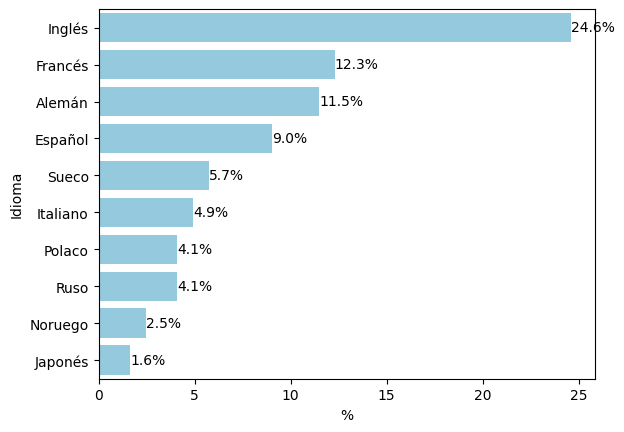

In [21]:
ax = sns.barplot(x=idiomas["%"].head(10), y=idiomas["Idioma"].head(10), color="Skyblue")

# Agregar etiquetas con el porcentaje
ax.bar_label(ax.containers[0],
             labels=idiomas["%"].head(10).round(1).astype(str) + "%",
             label_type="edge")
plt.show()

## 9. Análisis de la edad al momento de recibir el premio

La edad al ganar es una variable cuantitativa continua que caracteriza el grado de madurez de los galardonados.

El resumen estadístico general de la edad refleja:
* **Edad mínima:** 42 años (Rudyard Kipling, 1907)
* **Edad máxima:** 88 años (Doris Lessing, 2007)
* **Media histórica:** 65.0 años
* **Mediana histórica:** 67.0 años
* **Rango Intercuartílico (IQR):** 57 a 73 años

Al comparar por género, la distribución de edades entre hombres (media de 65.1 años, mediana de 67.0) y mujeres (media de 64.0 años, mediana de 60.0) demuestra que ambos grupos reciben la distinción en etapas consolidadas de su carrera literaria.


In [22]:
nobel["Edad_al_ganar"].describe()

,Edad_al_ganar
count,122.000000
mean,64.959016
std,10.227493
min,42.000000
25%,57.000000
50%,67.000000
75%,73.000000
max,88.000000


In [23]:
menor = nobel["Edad_al_ganar"].min()
mayor = nobel["Edad_al_ganar"].max()
print(f"El ganador más joven tenia {menor} años al ganar el premio y el mayor tenia {mayor} años")

El ganador más joven tenia 42 años al ganar el premio y el mayor tenia 88 años


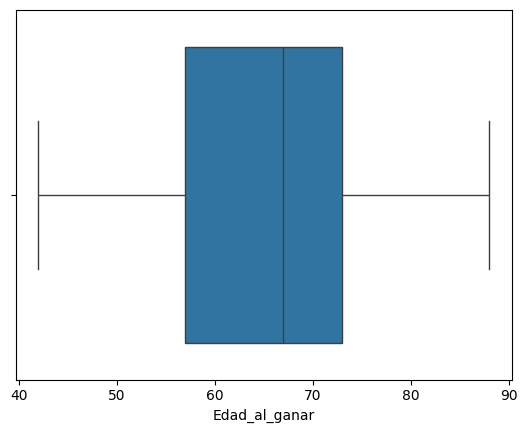

In [24]:
sns.boxplot(x=nobel["Edad_al_ganar"])
plt.show()

In [25]:
mujeres = nobel[nobel["Género"] == "Femenino"]
hombres = nobel[nobel["Género"] == "Masculino"]

In [26]:
mujeres["Edad_al_ganar"].describe()

,Edad_al_ganar
count,18.000000
mean,64.000000
std,12.947859
min,46.000000
25%,55.250000
50%,60.000000
75%,74.500000
max,88.000000


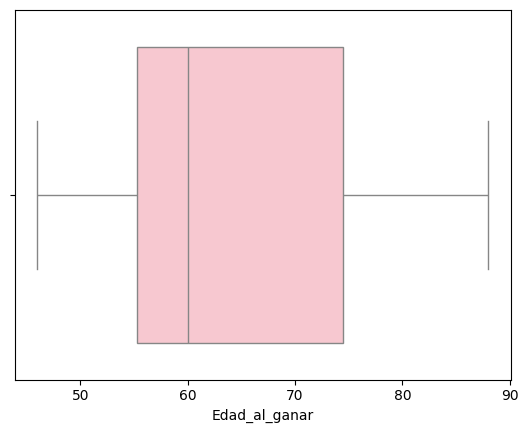

In [27]:
# Mujeres
sns.boxplot(x=mujeres["Edad_al_ganar"], color="pink")
plt.show()

In [28]:
hombres["Edad_al_ganar"].describe()

,Edad_al_ganar
count,104.000000
mean,65.125000
std,9.747977
min,42.000000
25%,58.000000
50%,67.000000
75%,73.000000
max,85.000000


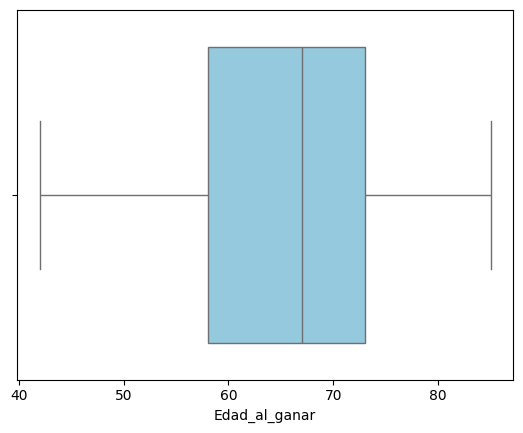

In [29]:
# Hombres
sns.boxplot(x=hombres["Edad_al_ganar"], color="skyblue")
plt.show()

## 10. Comparación temporal: Acumulado histórico (1901–2025) frente al Período Reciente (2006–2025)

Para determinar si las dinámicas del premio han evolucionado, se realiza un corte comparativo analizando los 20 años más recientes (2006–2025, $n=20$).

Los hallazgos principales de esta comparación son:
1. **Ponderación por Género:** Mientras que en la historia global las mujeres representan el $14.75\%$, en los últimos 20 años representan el **$40.0\%$** (8 de 20 premiados).
2. **Promedio de Edad:** La edad media de premiación aumentó de **65.0 años** en el histórico a **69.4 años** en las últimas dos décadas (con una mediana de 70.0 años).
3. **Distribución Continental Reciente:** Europa mantiene la mayoría con el $60.0\%$ (12 de 20), seguida por América ($20.0\%$), Asia ($15.0\%$) y África ($5.0\%$).
4. **Idiomas Recientes:** El inglés continúa liderando con el $30.0\%$ (6 de 20), seguido del francés ($15.0\%$) y el alemán ($10.0\%$), con presencia de lenguas como coreano, húngaro, chino, polaco, ruso, turco y noruego nynorsk.

In [30]:
ultimos_20_años = nobel[nobel["Año"] >= 2006]
ultimos_20_años.head()

,Año,Nombre,Nacionalidad,Continente,Género,Nacimiento,Edad_al_ganar,Idioma,Década
0,2025,László Krasznahorkai,Hungría,Europa,Masculino,1954,71,Húngaro,2020
1,2024,Han Kang,Corea del Sur,Asia,Femenino,1970,54,Coreano,2020
2,2023,Jon Fosse,Noruega,Europa,Masculino,1959,64,Noruego (nynorsk),2020
3,2022,Annie Ernaux,Francia,Europa,Femenino,1940,82,Francés,2020
4,2021,Abdulrazak Gurnah,Tanzania,África,Masculino,1948,73,Inglés,2020


In [31]:
# Comparación sencilla entre el período histórico y los últimos 20 años

print("Mujeres históricas:",
      round((nobel["Género"] == "Femenino").sum() / len(nobel) * 100, 2), "%")

print("Mujeres últimos 20 años:",
      round((ultimos_20_años["Género"] == "Femenino").sum() / len(ultimos_20_años) * 100, 2), "%")

print("Edad media histórica:",
      round(nobel["Edad_al_ganar"].mean(), 2))

print("Edad media últimos 20 años:",
      round(ultimos_20_años["Edad_al_ganar"].mean(), 2))

Mujeres históricas: 14.75 %
Mujeres últimos 20 años: 40.0 %
Edad media histórica: 64.96
Edad media últimos 20 años: 69.35


In [32]:
# Agrupar por continente y contar
continentes_ultimos_20 = ultimos_20_años.groupby("Continente")["Nombre"].count().reset_index()

# Renombrar las columnas
continentes_ultimos_20 = continentes_ultimos_20.rename(columns={
    "Continente": "Continentes",
    "Nombre": "Conteo"})

# Porcentaje
continentes_ultimos_20["%"] = round(continentes_ultimos_20["Conteo"] / continentes_ultimos_20["Conteo"].sum() * 100, 2)

# Ordenar de mayor a menor
continentes_ultimos_20 = continentes_ultimos_20.sort_values(by="Conteo", ascending=False)

print(continentes_ultimos_20)

  Continentes  Conteo     %
2      Europa      12  60.0
0     América       4  20.0
1        Asia       3  15.0
3      África       1   5.0


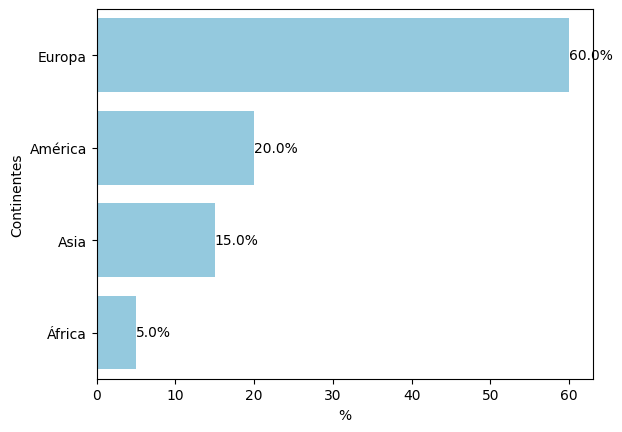

In [33]:
ax = sns.barplot(x=continentes_ultimos_20["%"], y=continentes_ultimos_20["Continentes"], color="skyblue")

# Agregar etiquetas con el porcentaje
ax.bar_label(ax.containers[0],
             labels=continentes_ultimos_20["%"].round(1).astype(str) + "%",
             label_type="edge")
plt.show()

In [34]:
# Agrupar por país y contar
paises_ultimos_20 = ultimos_20_años.groupby("Nacionalidad")["Nombre"].count().reset_index()

# Renombrar las columnas
paises_ultimos_20 = paises_ultimos_20.rename(columns={
    "Nacionalidad": "Países",
    "Nombre": "Conteo"})

# Porcentaje
paises_ultimos_20["%"] = round(paises_ultimos_20["Conteo"] / paises_ultimos_20["Conteo"].sum() * 100, 2)

# Ordenar de mayor a menor
paises_ultimos_20 = paises_ultimos_20.sort_values(by="Conteo", ascending=False)

print(paises_ultimos_20)

            Países  Conteo     %
6          Francia       3  15.0
5   Estados Unidos       2  10.0
11     Reino Unido       2  10.0
0          Austria       1   5.0
3            China       1   5.0
2           Canadá       1   5.0
4    Corea del Sur       1   5.0
1      Bielorrusia       1   5.0
7          Hungría       1   5.0
8          Noruega       1   5.0
9             Perú       1   5.0
10         Polonia       1   5.0
12         Rumanía       1   5.0
13          Suecia       1   5.0
14        Tanzania       1   5.0
15         Turquía       1   5.0


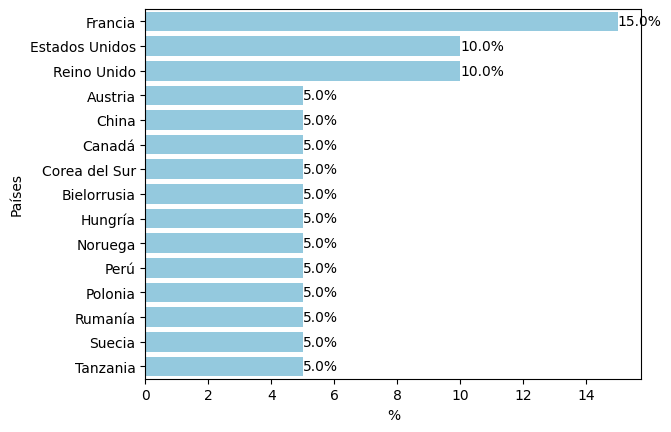

In [35]:
ax = sns.barplot(x=paises_ultimos_20["%"].head(15), y=paises_ultimos_20["Países"].head(15), color="skyblue")

# Agregar etiquetas con el porcentaje
ax.bar_label(ax.containers[0],
             labels=paises_ultimos_20["%"].head(15).round(1).astype(str) + "%",
             label_type="edge")
plt.show()

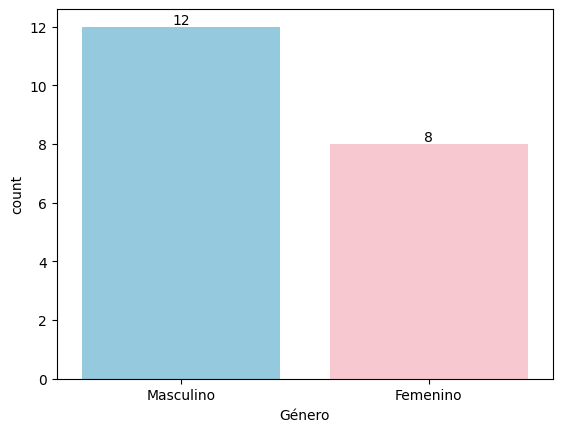

In [36]:
paleta_colores = {"Masculino": "skyblue", "Femenino": "pink"}
ax = sns.countplot(data=ultimos_20_años, x="Género", hue="Género", palette=paleta_colores)
# Agregar las etiquetas con los totales sobre cada barra
for p in ax.containers:
    ax.bar_label(p)
plt.show()

In [37]:
# Agrupar por idioma y contar
idiomas_ultimos_20 = ultimos_20_años.groupby("Idioma")["Nombre"].count().reset_index()

# Renombrar las columnas
idiomas_ultimos_20 = idiomas_ultimos_20.rename(columns={
    "Idioma": "Idioma",
    "Nombre": "Conteo"})

# Porcentaje
idiomas_ultimos_20["%"] = round(idiomas_ultimos_20["Conteo"] / idiomas_ultimos_20["Conteo"].sum() * 100, 2)

# Ordenar de mayor a menor
idiomas_ultimos_20 = idiomas_ultimos_20.sort_values(by="Conteo", ascending=False)

print(idiomas_ultimos_20.head(10))

              Idioma  Conteo     %
6             Inglés       6  30.0
4            Francés       3  15.0
0             Alemán       2  10.0
1              Chino       1   5.0
3            Español       1   5.0
2            Coreano       1   5.0
5            Húngaro       1   5.0
7  Noruego (nynorsk)       1   5.0
8             Polaco       1   5.0
9               Ruso       1   5.0


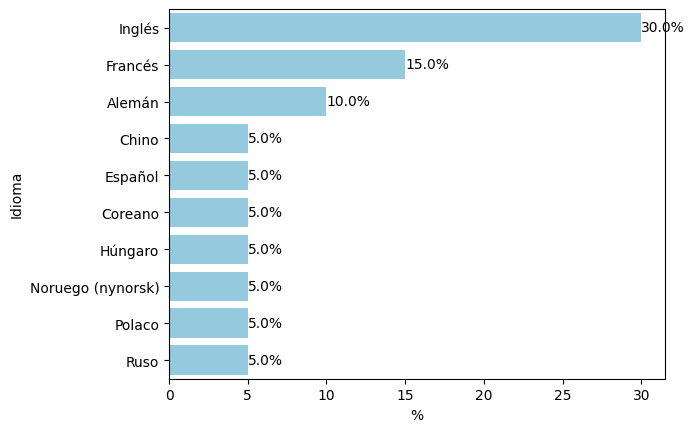

In [38]:
ax = sns.barplot(x=idiomas_ultimos_20["%"].head(10), y=idiomas_ultimos_20["Idioma"].head(10), color="Skyblue")

# Agregar etiquetas con el porcentaje
ax.bar_label(ax.containers[0],
             labels=idiomas_ultimos_20["%"].head(10).round(1).astype(str) + "%",
             label_type="edge")
plt.show()

In [39]:
ultimos_20_años["Edad_al_ganar"].describe()

,Edad_al_ganar
count,20.000000
mean,69.350000
std,10.322561
min,54.000000
25%,61.500000
50%,70.000000
75%,77.000000
max,88.000000


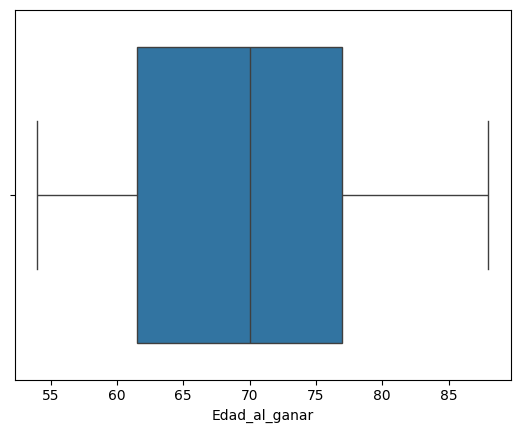

In [40]:
sns.boxplot(x=ultimos_20_años["Edad_al_ganar"])
plt.show()

## 11. Análisis bivariado: Género frente a Continente e Idioma

Al cruzar la variable género con el continente de origen y el idioma de escritura mediante porcentajes condicionados dentro de cada grupo, se observan las siguientes relaciones:

* **Género vs. Continente:**
  * **Mujeres:** El $61.1\%$ históricamente ($62.5\%$ en los últimos 20 años) proviene de Europa, y el $27.8\%$ ($25.0\%$ reciente) de América.
  * **Hombres:** El $75.0\%$ histórico ($58.3\%$ reciente) proviene de Europa, mostrando una mayor diversificación hacia Asia y África en el período reciente.

* **Género vs. Idioma:**
  * **Mujeres:** El inglés es la lengua más frecuente ($33.3\%$ histórico y $37.5\%$ reciente), seguido por el alemán, francés, polaco, ruso y coreano.
  * **Hombres:** El inglés lidera con $23.1\%$ histórico ($25.0\%$ reciente), seguido del francés ($13.5\%$ histórico, $16.7\%$ reciente) y el español ($9.6\%$).

In [41]:
# Histórico
# Género vs. continente
genero_continente = pd.crosstab(nobel["Continente"], nobel["Género"])
print(genero_continente)

# Porcentaje dentro de cada género
print("\nPorcentaje dentro de cada género:")
print(round(genero_continente.div(genero_continente.sum(axis=0), axis=1) * 100, 2))

Género      Femenino  Masculino
Continente                     
América            5         14
Asia               1          7
Europa            11         78
Oceanía            0          1
África             1          4

Porcentaje dentro de cada género:
Género      Femenino  Masculino
Continente                     
América        27.78      13.46
Asia            5.56       6.73
Europa         61.11      75.00
Oceanía         0.00       0.96
África          5.56       3.85


In [42]:
# Últimos 20 años
# Género vs. continente
genero_continente = pd.crosstab(ultimos_20_años["Continente"], ultimos_20_años["Género"])
print(genero_continente)

# Porcentaje dentro de cada género
print("\nPorcentaje dentro de cada género:")
print(round(genero_continente.div(genero_continente.sum(axis=0), axis=1) * 100, 2))

Género      Femenino  Masculino
Continente                     
América            2          2
Asia               1          2
Europa             5          7
África             0          1

Porcentaje dentro de cada género:
Género      Femenino  Masculino
Continente                     
América         25.0      16.67
Asia            12.5      16.67
Europa          62.5      58.33
África           0.0       8.33


### Género vs Continente

Histórico global: Tanto en hombres como en mujeres, el premio es fuertemente eurocéntrico (75% de los hombres y 61% de las mujeres son europeos).   

Últimos 20 años: La tendencia europea se mantiene predominante (62.5% de mujeres y 58% de hombres), pero América y Asia conservan presencia relevante.

In [43]:
# Histórico
# Género vs. idioma
genero_idioma = pd.crosstab(nobel["Idioma"], nobel["Género"])
print(genero_idioma)

# Porcentaje dentro de cada género
print("\nPorcentaje dentro de cada género:")
print(round(genero_idioma.div(genero_idioma.sum(axis=0), axis=1) * 100, 2))

Género             Femenino  Masculino
Idioma                                
Alemán                    3         11
Bengalí / Inglés          0          1
Checo                     0          1
Chino                     0          2
Coreano                   1          0
Danés                     0          2
Danés / Alemán            0          1
Español                   1         10
Finlandés                 0          1
Francés                   1         14
Griego                    0          2
Hebreo                    0          1
Húngaro                   0          2
Inglés                    6         24
Inglés / Francés          0          1
Islandés                  0          1
Italiano                  1          5
Japonés                   0          2
Noruego                   1          2
Noruego (nynorsk)         0          1
Occitano                  0          1
Polaco                    2          3
Portugués                 0          1
Ruso                     

In [44]:
# Últimos 20 años
# Género vs. idioma
genero_idioma = pd.crosstab(ultimos_20_años["Idioma"], ultimos_20_años["Género"])
print(genero_idioma)

# Porcentaje dentro de cada género
print("\nPorcentaje dentro de cada género:")
print(round(genero_idioma.div(genero_idioma.sum(axis=0), axis=1) * 100, 2))

Género             Femenino  Masculino
Idioma                                
Alemán                    1          1
Chino                     0          1
Coreano                   1          0
Español                   0          1
Francés                   1          2
Húngaro                   0          1
Inglés                    3          3
Noruego (nynorsk)         0          1
Polaco                    1          0
Ruso                      1          0
Sueco                     0          1
Turco                     0          1

Porcentaje dentro de cada género:
Género             Femenino  Masculino
Idioma                                
Alemán                 12.5       8.33
Chino                   0.0       8.33
Coreano                12.5       0.00
Español                 0.0       8.33
Francés                12.5      16.67
Húngaro                 0.0       8.33
Inglés                 37.5      25.00
Noruego (nynorsk)       0.0       8.33
Polaco                 12.5  

### Idioma y Cultura (Género vs Idioma)

#### Histórico global
  - En mujeres, el Inglés es el idioma predominante ($33.33\%$), seguido del Alemán ($16.67\%$).
  En hombres, el Inglés también lidera ($23.08\%$), seguido por el Francés ($13.46\%$) y el Español ($9.62\%$).
  
#### Últimos 20 años:
  - En mujeres, el Inglés mantiene la mayor concentración ($37.50\%$), con presencia menor e igualitaria ($12.50\%$ cada uno) de Alemán, Coreano, Francés, Polaco y Ruso.
  - En hombres, el Inglés predomina ($25.00\%$), seguido del Francés ($16.67\%$), repartiéndose el porcentaje restante ($8.33\%$ cada uno) entre Alemán, Chino, Español, Húngaro, Noruego, Sueco y Turco.

## 12. Análisis de la secuencia de alternancia de género (2018–2025)

Al observar la serie cronológica reciente entre 2018 y 2025, se identifica un patrón de alternancia consecutiva año a año:

$$\text{2018 (Mujer)} \rightarrow \text{2019 (Hombre)} \rightarrow \text{2020 (Mujer)} \rightarrow \text{2021 (Hombre)} \rightarrow \text{2022 (Mujer)} \rightarrow \text{2023 (Hombre)} \rightarrow \text{2024 (Mujer)} \rightarrow \text{2025 (Hombre)}$$

### Interpretación estadística prudente para 2026:
Si se plantea únicamente como **hipótesis de trabajo o escenario de continuidad** que este patrón de alternancia se mantendrá en la edición de 2026, el género del siguiente galardonado correspondería a una **mujer**.

Sin embargo, es fundamental recalcar que esta secuencia abarca un período de solo 8 años con muy pocas transiciones observadas. Por ello, constituye un patrón descriptivo relevante de la serie reciente, pero no debe interpretarse como una regla determinista ni como una ley matemática infalible.

In [45]:
# Comprobación sencilla de la alternancia 2018–2025

alternancia_desde_2018 = nobel[nobel["Año"] >= 2018].sort_values("Año", ascending=False)

display(alternancia_desde_2018[["Año", "Nombre", "Género"]])

print("Secuencia observada:")
print(alternancia_desde_2018[["Año", "Género"]].to_string(index=False))

# La secuencia observada alterna Mujer-Hombre desde 2018 hasta 2025.
# Esto describe lo ocurrido en esos ocho años; no demuestra una regla permanente.

,Año,Nombre,Género
0,2025,László Krasznahorkai,Masculino
1,2024,Han Kang,Femenino
2,2023,Jon Fosse,Masculino
3,2022,Annie Ernaux,Femenino
4,2021,Abdulrazak Gurnah,Masculino
5,2020,Louise Glück,Femenino
6,2019,Peter Handke,Masculino
7,2018,Olga Tokarczuk,Femenino


Secuencia observada:
 Año    Género
2025 Masculino
2024  Femenino
2023 Masculino
2022  Femenino
2021 Masculino
2020  Femenino
2019 Masculino
2018  Femenino


In [46]:
# Transiciones Hombre -> Mujer observadas entre 2018 y 2025

serie = alternancia_desde_2018.sort_values("Año").reset_index(drop=True)

hombre_mujer = 0
total_desde_hombre = 0

for i in range(1, len(serie)):
    if serie.loc[i - 1, "Género"] == "Masculino":
        total_desde_hombre += 1
        if serie.loc[i, "Género"] == "Femenino":
            hombre_mujer += 1

print("Transiciones Hombre -> Mujer:", hombre_mujer)
print("Transiciones cuyo año anterior fue Hombre:", total_desde_hombre)

if total_desde_hombre > 0:
    print(
        "Frecuencia observada Hombre -> Mujer:",
        round(hombre_mujer / total_desde_hombre * 100, 2),
        "%"
    )

Transiciones Hombre -> Mujer: 3
Transiciones cuyo año anterior fue Hombre: 3
Frecuencia observada Hombre -> Mujer: 100.0 %


In [47]:
alternancia_desde_2018 = nobel[nobel["Año"] >= 2018]
alternancia_desde_2018

,Año,Nombre,Nacionalidad,Continente,Género,Nacimiento,Edad_al_ganar,Idioma,Década
0,2025,László Krasznahorkai,Hungría,Europa,Masculino,1954,71,Húngaro,2020
1,2024,Han Kang,Corea del Sur,Asia,Femenino,1970,54,Coreano,2020
2,2023,Jon Fosse,Noruega,Europa,Masculino,1959,64,Noruego (nynorsk),2020
3,2022,Annie Ernaux,Francia,Europa,Femenino,1940,82,Francés,2020
4,2021,Abdulrazak Gurnah,Tanzania,África,Masculino,1948,73,Inglés,2020
5,2020,Louise Glück,Estados Unidos,América,Femenino,1943,77,Inglés,2020
6,2019,Peter Handke,Austria,Europa,Masculino,1942,77,Alemán,2010
7,2018,Olga Tokarczuk,Polonia,Europa,Femenino,1962,56,Polaco,2010


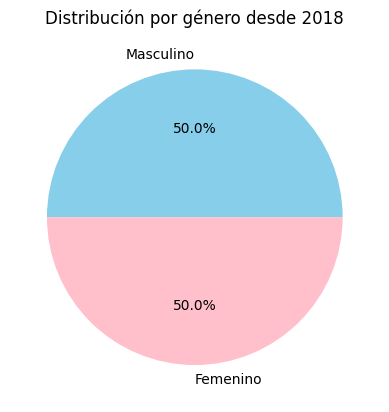

In [48]:
# Agrupar por género y contar
conteo_genero = alternancia_desde_2018["Género"].value_counts()

# Gráfico circular
plt.pie(
    conteo_genero.values,       # valores numéricos
    labels=conteo_genero.index, # etiquetas (Masculino, Femenino)
    autopct="%1.1f%%",          # porcentajes
    colors=["skyblue", "pink"])       # tu lista de colores definida antes

plt.title("Distribución por género desde 2018")
plt.show()


### Interpretación correcta para 2026

Una formulación estadísticamente prudente sería:

> **Si se asumiera, únicamente como escenario, que la alternancia observada entre 2018 y 2025 continúa en 2026, el siguiente género esperado por esa regla sería femenino. Sin embargo, la muestra de transiciones es demasiado pequeña.


## 13. Resumen de frecuencias y análisis de escenarios

Para evitar ambigüedades, diferenciamos claramente tres métricas derivadas de los datos:

1. **Frecuencia Relativa Histórica:**  
   $$P(\text{Mujer}) = \frac{18}{122} \approx 14.75\%$$  
   Describe la proporción global de mujeres entre todas las personas galardonadas desde 1901.

2. **Frecuencia Relativa Reciente (2006–2025):**  
   $$P(\text{Mujer} \mid \text{Últimos 20 años}) = \frac{8}{20} = 40.0\%$$  
   Refleja la ponderación observada en las decisiones del comité durante las últimas dos décadas.

3. **Escenario Condicionado por la Serie Reciente:**  
   Bajo el supuesto explícito de continuidad del patrón de alternancia 2018–2025, el escenario proyectado para **2026** corresponde a una **galardonada de género femenino**. Este resultado es consecuencia del supuesto de inercia y no de un cálculo de certeza probabilística.

In [49]:
# Probabilidades/frecuencias sencillas

mujeres = nobel[nobel["Género"] == "Femenino"]
mujeres_ultimos_20 = ultimos_20_años[ultimos_20_años["Género"] == "Femenino"]

p_mujer_historica = len(mujeres) / len(nobel)
p_mujer_reciente = len(mujeres_ultimos_20) / len(ultimos_20_años)

print("Probabilidad/frecuencia histórica de que el ganador sea mujer:",
      round(p_mujer_historica * 100, 2), "%")

print("Probabilidad/frecuencia en los últimos 20 años de que el ganador sea mujer:",
      round(p_mujer_reciente * 100, 2), "%")

print("Resultado de la secuencia 2018–2025:")
print("Si se plantea como supuesto que la alternancia continúa, el escenario para 2026 sería: Mujer.")

# Importante: la frecuencia histórica y la reciente son frecuencias relativas.
# El escenario de 2026 depende del supuesto de continuidad y no es una certeza.

Probabilidad/frecuencia histórica de que el ganador sea mujer: 14.75 %
Probabilidad/frecuencia en los últimos 20 años de que el ganador sea mujer: 40.0 %
Resultado de la secuencia 2018–2025:
Si se plantea como supuesto que la alternancia continúa, el escenario para 2026 sería: Mujer.


## 14. Evaluación del Perfil Combinado (Perfil A)

Con el fin de analizar la densidad de frecuencia conjunta de las características más representativas de la historia del premio, evaluamos el denominado **Perfil A**, definido formalmente bajo los siguientes tres criterios simultáneos:
* **Ubicación:** Continente Europeo.
* **Idioma:** Inglés, Francés o Alemán.
* **Edad al ganar:** Entre 60 y 75 años (franja modal de madurez).

### Resultados del cálculo:
* **Frecuencia del Perfil A en el acumulado histórico (1901–2025):**  
  **18 de 122 galardonados ($14.75\%$)** cumplen de forma estricta los tres criterios.
* **Frecuencia del Perfil A en los últimos 20 años (2006–2025):**  
  **3 de 20 galardonados ($15.00\%$)** (Jean-Marie Gustave Le Clézio en 2008, Patrick Modiano en 2014 y Kazuo Ishiguro en 2017).

Este resultado confirma que el Perfil A mantiene una consistencia notable tanto en el horizonte de largo plazo como en la historia reciente, sirviendo como punto de referencia para medir la masa modal del galardón.

In [50]:
# Perfil A: Europa + Inglés/Francés/Alemán + edad 60–75
idiomas_perfil_a = ["Inglés", "Francés", "Alemán"]

perfil_a_hist = nobel[
    (nobel["Continente"] == "Europa") &
    (nobel["Idioma"].isin(idiomas_perfil_a)) &
    (nobel["Edad_al_ganar"].between(60, 75))
].copy()

perfil_a_rec = ultimos_20_años[
    (ultimos_20_años["Continente"] == "Europa") &
    (ultimos_20_años["Idioma"].isin(idiomas_perfil_a)) &
    (ultimos_20_años["Edad_al_ganar"].between(60, 75))
].copy()

print(f"Perfil A histórico: {len(perfil_a_hist)} de {len(nobel)} "
      f"= {len(perfil_a_hist)/len(nobel):.2%}")

print(f"Perfil A reciente: {len(perfil_a_rec)} de {len(ultimos_20_años)} "
      f"= {len(perfil_a_rec)/len(ultimos_20_años):.2%}")

display(
    perfil_a_hist[["Año", "Nombre", "Género", "Continente", "Idioma", "Edad_al_ganar"]]
    .sort_values("Año")
)


Perfil A histórico: 18 de 122 = 14.75%
Perfil A reciente: 3 de 20 = 15.00%


,Año,Nombre,Género,Continente,Idioma,Edad_al_ganar
121,1901,Sully Prudhomme,Masculino,Europa,Francés,62
113,1908,Rudolf Eucken,Masculino,Europa,Alemán,62
103,1919,Carl Spitteler,Masculino,Europa,Alemán,74
97,1925,George Bernard Shaw,Masculino,Europa,Inglés,69
95,1927,Henri Bergson,Masculino,Europa,Francés,68
90,1932,John Galsworthy,Masculino,Europa,Inglés,65
81,1946,Hermann Hesse,Masculino,Europa,Alemán,69
79,1948,T. S. Eliot,Masculino,Europa,Inglés,60
75,1952,François Mauriac,Masculino,Europa,Francés,67
67,1960,Saint-John Perse,Masculino,Europa,Francés,73


## 15. Factores cualitativos, institucionales y límites de la inferencia estadística

Para comprender por qué el perfil de un galardonado del Premio Nobel de Literatura no puede reducirse a métricas demográficas simples ni predecirse mediante datos históricos, es necesario integrar el contexto normativo e institucional (*NobelPrize.org*):

### 1. Criterio literario y fines del galardón
El testamento de Alfred Nobel establece que el premio debe otorgarse a la persona que haya producido *"en el campo de la literatura la obra más destacada en una dirección ideal"*. La evaluación de la Academia Sueca prioriza el mérito artístico y la innovación del lenguaje, dimensiones que no se capturan en variables cuantitativas.

### 2. Geopolítica, marco social, *timing* e inclusión
A lo largo de la historia, el comité ha otorgado distinciones que responden al momento histórico global (*timing*): guerras, crisis humanitarias, regímenes autoritarios, la defensa de la libertad de prensa o la reivindicación de causas sociales y de inclusión. Estos factores exógenos reorientan temporalmente las decisiones del jurado.

### 3. Presión de la opinión pública, *lobbies* y grupos de poder
Las campañas de visibilización y traducción orquestadas por grandes casas editoriales, el cabildeo académico (*lobbies*), la diplomacia cultural y la atención mediática internacional ejercen una influencia real sobre los autores que logran posicionarse en la agenda del comité.

### 4. Decisones atípicas que rompen los moldes tradicionales
La historia del galardón demuestra que el jurado rompe sus propios esquemas con elecciones impredecibles:
* **Winston Churchill (1953):** Premiado por sus escritos históricos, biografías y su oratoria política en un contexto geopolítico de posguerra.
* **Bob Dylan (2016):** Premiado por crear nuevas expresiones poéticas dentro de la tradición musical, desafiando las fronteras convencionales de la literatura.

### 5. El hito institucional de 2018
Tras la crisis institucional de 2018 que llevó a posponer el premio y a reformar los estatutos de la Fundación Nobel, la Academia incorporó miembros independientes. La alternancia observada entre 2018 y 2025 es reflejo de esta búsqueda activa de equidad e inclusión, no de un algoritmo matemático.

# 16. Conclusiones finales

1. **Universo de datos y premios compartidos:** El dataset consolidado contiene 122 personas galardonadas en 118 años de concesión (1901–2025). Las cuatro ocasiones con premio compartido (1904, 1917, 1966 y 1974) explican la diferencia entre ambas cifras.
2. **Concentración geográfica e idiomática:** Existe una clara hegemonía histórica europea (72.95 %, 89 de 122 galardonados) y un predominio de las obras escritas en inglés (24.59 %), francés (12.30 %) y alemán (11.48 %).
3. **Evolución de la representación femenina:** En el registro histórico acumulado, las mujeres representan el 14.75 % (18 de 122). Sin embargo, en el período reciente (2006–2025) esta cifra asciende al 40.0 % (8 de 20), demostrando un cambio estructural respecto al siglo XX.
4. **Perfil de edad consolidado:** La mediana de edad al recibir el premio es de 67 años a nivel histórico y aumenta a 70 años en los últimos 20 años, situando la masa modal entre los 60 y 75 años.
5. **Patrón de alternancia de género (2018–2025):** La secuencia observada entre 2018 y 2025 muestra una alternancia ininterrumpida entre mujeres y hombres durante 8 entregas consecutivas.
6. **Escenario prospectivo para 2026:** Bajo el supuesto condicionado de que la racha de alternancia continúe, el escenario proyectado señalaría a una autora de género femenino.
7. **Consistencia del Perfil A:** La combinación de origen europeo, idioma hegemónico (inglés, francés o alemán) y edad entre 60 y 75 años representa el 14.75 % histórico y el 15.00 % reciente, sirviendo como medida de la masa modal del galardón.

### Conclusión general
El proyecto ofrece una caracterización rigurosa de las tendencias históricas del Premio Nobel de Literatura. La conclusión fundamental es que **es imposible predecir con certeza cuantitativa quién ganará el premio**. Aunque los datos muestran inercias claras, la decisión final de la Academia Sueca es un proceso cualitativo condicionado por el mérito artístico, el contexto geopolítico, el *timing* social, los *lobbies* editoriales, la opinión pública y decisiones heterodoxas que escapan a cualquier modelo numérico.

## 17. Limitaciones

- El tamaño de la muestra es pequeño para realizar inferencias predictivas complejas.
- Los ganadores no constituyen una muestra aleatoria de una población.
- Las decisiones de la Academia dependen de factores que no aparecen en esta base.
- Las variables `Nacionalidad`, `Continente` e `Idioma` dependen de criterios de clasificación que deben documentarse.
- Una asociación histórica no implica causalidad.
- Una racha temporal corta puede desaparecer sin que exista una “ruptura” de una regla estadística.
- Para construir un verdadero modelo predictivo sería necesario definir una variable objetivo, seleccionar predictores disponibles antes de cada premio y realizar validación temporal fuera de muestra.

### Fuentes

La fuente primaria recomendada para contrastar los registros es **Nobel Prize / Nobel Foundation** y su conjunto de datos enlazados.

- https://www.nobelprize.org/
- https://data.nobelprize.org/specification/

El objetivo de esas fuentes en este proyecto es principalmente **validar y documentar el conjunto de datos**, no sustituir el análisis realizado en Python.


# 18. Resumen ejecutivo para presentación de resultados

> El presente estudio analiza a las 122 personas galardonadas con el Premio Nobel de Literatura entre 1901 y 2025. Los resultados demuestran una evolución clara entre el patrón histórico del siglo XX (marcadamente europeo, masculino y centrado en grandes lenguas continentales) y la dinámica de las últimas dos décadas.
>
> En el período reciente (2006–2025), la participación de mujeres se ha triplicado respecto al promedio histórico (alcanzando el 40 %), la mediana de edad se ha elevado a los 70 años y se aprecia un patrón ininterrumpido de alternancia de género a partir de la reestructuración de la Academia en 2018.
>
> Cruzando estos elementos, el escenario prospectivo más compatible con las tendencias recientes para la edición de **2026** corresponde a una **escritora de género femenino, en un rango de edad de 60 a 75 años, proveniente de una región o tradición lingüística de diversificación**.
>
> Sin embargo, se enfatiza de forma tajante que la asignación del galardón obedece al mérito literario, a dinámicas geopolíticas, a la influencia de *lobbies* y a deliberaciones cualitativas impredecibles, por lo que este perfil representa un escenario de continuidad histórica y no una predicción matemática.

 # Convertir a PDF

In [5]:
# !apt-get update && apt-get install -y texlive-xetex texlive-fonts-recommended texlive-plain-generic pandoc

In [7]:
# !pip install nbconvert

In [59]:
# !apt-get install texlive texlive-xetex texlive-latex-extra pandoc

In [10]:
# Ubicación del proyecto
%cd "/content/drive/MyDrive/Colab Notebooks/Nobel"

/content/drive/MyDrive/Colab Notebooks/Nobel


In [11]:
!jupyter nbconvert --to pdf --output proyecto_nobel.pdf nobel_de_literatura.ipynb

[NbConvertApp] Converting notebook nobel_de_literatura.ipynb to pdf
[NbConvertApp] Support files will be in proyecto_nobel_files/
[NbConvertApp] Making directory ./proyecto_nobel_files
[NbConvertApp] Writing 137512 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 374284 bytes to proyecto_nobel.pdf


In [12]:
# Descargar el archivo
from google.colab import files
files.download('proyecto_nobel.pdf')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# FIN